# Preprocessing Technique 4: Normalization / Scaling
IT25102115 - Malka H. A. G.
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Feature scaling** rescales numeric features onto a common range or distribution so that no single feature dominates a model purely because of its numeric magnitude. Two common approaches:
- **Min-Max Normalization** - rescales values into a fixed **[0, 1]** range.
- **Standardization (Z-score scaling)** - rescales values to have mean 0 and standard deviation 1.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [3]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [5]:
df_s = df.copy()
df_s['Bare_Nuclei'] = df_s['Bare_Nuclei'].replace('?', np.nan).astype(float)
df_s['Bare_Nuclei'] = df_s['Bare_Nuclei'].fillna(df_s['Bare_Nuclei'].median())
feature_cols = ['Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
                'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei',
                'Bland_Chromatin','Normal_Nucleoli','Mitoses']
df_s[feature_cols] = df_s[feature_cols].astype(float)
df_s[feature_cols].describe().round(2)

,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses
count,699.00,699.00,699.00,699.00,699.00,699.00,699.00,699.00,699.00
mean,4.42,3.13,3.21,2.81,3.22,3.49,3.44,2.87,1.59
std,2.82,3.05,2.97,2.86,2.21,3.62,2.44,3.05,1.72
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,1.00,1.00,1.00,2.00,1.00,2.00,1.00,1.00
50%,4.00,1.00,1.00,1.00,2.00,1.00,3.00,1.00,1.00
75%,6.00,5.00,5.00,4.00,4.00,5.00,5.00,4.00,1.00
max,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00


## 2. Why This Technique Was Needed
At first glance, all 9 features already share the same **1-10 scale**, so scaling may seem unnecessary. However:
- The features have **different variances and spreads** (some cluster tightly near 1, others spread across the full range - confirmed by the **std** row above), which still biases **distance-based algorithms** like **SVM** and **KNN**, both candidates for our Step 3 modelling.
- Algorithms that use **gradient-based optimization** (e.g. Logistic Regression, Neural Networks) **converge faster and more reliably** on standardized inputs.
- Scaling is a **required, low-cost step** with no downside for tree-based models (Decision Trees/Random Forest are scale-invariant) and a **meaningful benefit** for margin/distance-based models - so it is worth doing regardless of which two algorithms we finalise.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

X = df_s[feature_cols]

minmax = MinMaxScaler()
X_minmax = pd.DataFrame(minmax.fit_transform(X), columns=feature_cols)

standard = StandardScaler()
X_standard = pd.DataFrame(standard.fit_transform(X), columns=feature_cols)

print("BEFORE scaling (raw 1-10 scores):")
print(X.describe().loc[['mean','std','min','max']].round(2))

print("\nAFTER Min-Max scaling (range 0-1):")
print(X_minmax.describe().loc[['mean','std','min','max']].round(2))

print("\nAFTER Standardization (mean=0, std=1):")
print(X_standard.describe().loc[['mean','std','min','max']].round(2))

BEFORE scaling (raw 1-10 scores):
      Clump_Thickness  Uniformity_of_Cell_Size  Uniformity_of_Cell_Shape  \
mean             4.42                     3.13                      3.21   
std              2.82                     3.05                      2.97   
min              1.00                     1.00                      1.00   
max             10.00                    10.00                     10.00   

      Marginal_Adhesion  Single_Epithelial_Cell_Size  Bare_Nuclei  \
mean               2.81                         3.22         3.49   
std                2.86                         2.21         3.62   
min                1.00                         1.00         1.00   
max               10.00                        10.00        10.00   

      Bland_Chromatin  Normal_Nucleoli  Mitoses  
mean             3.44             2.87     1.59  
std              2.44             3.05     1.72  
min              1.00             1.00     1.00  
max             10.00            10.00 

## 3. EDA Visualization & Interpretation

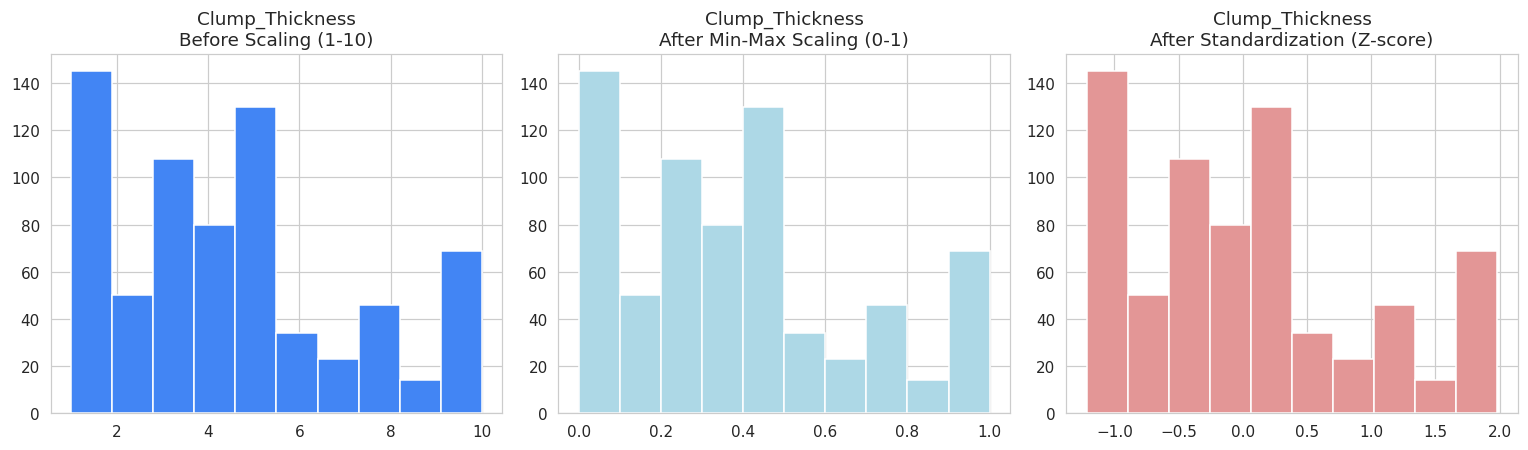

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
feat = 'Clump_Thickness'

axes[0].hist(X[feat], bins=10, color='#4285F4', edgecolor='white')
axes[0].set_title(f'{feat}\nBefore Scaling (1-10)')

axes[1].hist(X_minmax[feat], bins=10, color='#ADD8E6', edgecolor='white')
axes[1].set_title(f'{feat}\nAfter Min-Max Scaling (0-1)')

axes[2].hist(X_standard[feat], bins=10, color='#E39696', edgecolor='white')
axes[2].set_title(f'{feat}\nAfter Standardization (Z-score)')

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/04_scaling_comparison.png', bbox_inches='tight')
plt.show()

**Interpretation:** All three histograms have the **exact same shape** - scaling is a linear transformation, so it repositions values without distorting the underlying distribution or relationships between benign/malignant cases. Only the **x-axis scale changes**: raw scores (1-10) become 0-1 (Min-Max) or centred around 0 with unit spread (Standardization). This confirms scaling preserves all diagnostic information while making the feature numerically comparable to the other 8 features.

## 4. Summary
| Item | Result |
|---|---|
| Technique | Feature scaling |
| Methods compared | Min-Max Normalization, Standardization (Z-score) |
| Features affected | All 9 predictive features |
| Why needed | Different variances across features bias distance-based models (SVM, KNN); speeds up gradient-based convergence |
| Effect on distribution shape | None - scaling is a linear transform, shape is preserved |
| Recommended default | Standardization, since SVM (a leading model candidate) performs best with zero-mean, unit-variance input |